# Active subspaces of the JAG inertial confinement fusion ensemble: 15 anonymous implosion scalars

Stored data from

R. Anirudh, J. J. Thiagarajan, P.-T. Bremer and B. K. Spears, *Improved surrogates in inertial confinement
fusion with manifold and cycle consistencies*, Proceedings of the National Academy of Sciences
117(18):9741–9746, 2020. [doi:10.1073/pnas.1916634117](https://doi.org/10.1073/pnas.1916634117)

Rushil Anirudh (1), Jayaraman J. Thiagarajan (1), Peer-Timo Bremer (1, 2), Brian K. Spears (3)

1 Center for Applied Scientific Computing, Lawrence Livermore National Laboratory, Livermore, CA;
2 Center for Extreme Data Management Analysis and Visualization, University of Utah, Salt Lake City, UT;
3 Design Physics Division, Lawrence Livermore National Laboratory, Livermore, CA
(affiliations as in the published article's Crossref record).

Data: the 10,000 JAG runs released by the authors in the GitHub repository
[llnl/macc](https://github.com/llnl/macc) (`data/icf-jag-10k.tar.gz`, MIT licence). Page numbers below refer
to the arXiv preprint of the article (arXiv:1912.08113v1), which is the version read for this notebook.

Notebook: Claude (Anthropic) for P. Constantine, 2026

In [1]:
%matplotlib inline
import itertools
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.spatial import cKDTree
import active_subspaces as ac

SEED = 646                        # the only seed: every bootstrap and permutation below draws from it
t_start = time.perf_counter()
warnings.simplefilter('once', ac.ValidityWarning)

## Summary

Anirudh et al. trained neural-network surrogates of JAG, a semi-analytic inertial confinement fusion (ICF)
implosion simulator of Lawrence Livermore National Laboratory, and released 10,000 of its runs: five inputs
and fifteen diagnostic scalars, none named and none with units, so this data set is anonymous (inputs
$x_1,\dots,x_5$, outputs $s_{00},\dots,s_{14}$). Without gradients, the notebook estimates them by local linear
fits on all 10,000 rows and finds one dominant direction for the headline output $s_{00}$ (the first stored
column): the gap $\lambda_1/\lambda_2$ depends on the number of neighbours per fit (9.19 with 8, 24.41 with 40) and is
18.1 from the gradients of a global degree-6 polynomial, while the direction itself barely moves (subspace
distance to the polynomial's at most 0.0255), and a one-variable polynomial on it has leave-one-out $R^2$ 0.9758. In all
fifteen scalars the first direction lies in the plane of $x_2$ and $x_3$ (no weight of $x_1$, $x_4$, $x_5$ above
0.0150 in absolute value), but several columns also depend on $x_5$: for $s_{03}$, $s_{07}$ and $s_{09}$ a polynomial in $(x_2, x_3)$ alone
has leave-one-out $R^2$ of only 0.8658–0.9269, and adding $x_5$ raises it to 0.9874–0.9974.

## Active subspaces in brief

For a function $f(\mathbf{x})$ of $m$ inputs with density $\rho$, the active subspace is spanned by the
leading eigenvectors of $\mathbf{C} = \int \nabla f\, \nabla f^\top \rho\, d\mathbf{x}$; a large gap after
the $n$-th eigenvalue means that $f$ varies mostly along the $n$ active variables
$\mathbf{y} = \mathbf{W}_1^\top \mathbf{x}$, which a sufficient summary plot of $f$ against $\mathbf{y}$
shows. Without gradients, $\mathbf{C}$ can be estimated from gradients of local linear fits to nearby
samples, or from a global fit. Inputs are scaled to $[-1, 1]$ before the estimate, so the eigenvectors are
in these scaled coordinates. See P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction
in Parameter Studies*, SIAM, 2015, [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

**Simulator.** The paper's data come from "the semi-analytical ICF simulator described in [1]" (p. 4; its
reference [1] is a conference abstract of Gaffney, Springer and Collins). The paper gives no equations of it.
The README of the authors' repository describes JAG: inside the hotspot an analytic spatial profile
(Betti et al. 2002; Springer et al. 2013), coupled ODEs for the energy balance of the problem (Betti et al.
2015), with terms for radiation, electron conduction, alpha heating and other processes, and a thin-shell
model of the 3D hydrodynamic evolution of the hotspot, post-processed into X-ray images and scalars. The
README adds that "JAG inputs do not relate to actual experimental observables, rather the state of the
implosion once the laser drive has switched off". JAG is not released, so the runs cannot be repeated.

**Function studied here.** For each stored column $j$, $f = s_j(\mathbf{x})$ with $\mathbf{x} = (x_1,\dots,x_5)$
the released inputs: one JAG run per row, nothing else computed.

**Inputs** ($m = 5$). The paper states a "5-dimensional input parameter space" sampled by a Latin hypercube
of 1 million points (p. 4) and speaks of process inputs only in general terms ("say target and laser
settings for ICF", p. 2); its self-consistency test scans each input between "the min and max ranges of that
parameter" (p. 5), so the inputs have bounds, but the paper does not give them. Neither the paper nor the
repository names the five inputs, gives units, or says whether the released values are physical or scaled.
The box below is read from the data (each input fills it: see the checks), not from the paper; the notebook
treats the inputs as uniform on it.

In [2]:
# The five inputs as released, in the column order of jag_icf_inputs.csv. Names and units are not released;
# the box is the smallest one with round end points that holds the data (this data set's choice).
LOWER = np.array([-0.3, 0.0, 0.0, -0.3, -0.3])
UPPER = np.array([0.3, 1.0, 1.0, 0.3, 0.3])
NAMES = ['x1', 'x2', 'x3', 'x4', 'x5']
space = ac.Uniform(LOWER, UPPER, names=NAMES)
print(f"{'input':6s} {'lower':>6s} {'upper':>6s}")
for n, a, b in zip(NAMES, LOWER, UPPER):
    print(f'{n:6s} {a:6.2f} {b:6.2f}')

input   lower  upper
x1      -0.30   0.30
x2       0.00   1.00
x3       0.00   1.00
x4      -0.30   0.30
x5      -0.30   0.30


| input | range in the data | units | what is known | source |
|---|---|---|---|---|
| $x_1$, $x_4$, $x_5$ | $[-0.3, 0.3]$ each | not given | symmetric about 0; meaning not given | `jag_icf_inputs.csv` |
| $x_2$, $x_3$ | $[0, 1]$ each | not given | meaning not given | `jag_icf_inputs.csv` |

**Outputs.** "15 diagnostic scalar quantities such as yield, ion temperature, pressure, etc." (p. 4), plus four
64 × 64 X-ray images per run (not used here). Which column is which quantity is not released. The stored values
lie in (0, 1) and the paper's Table 1 (p. 6) reports surrogate accuracy on them, so the values look scaled,
but no scaling is documented in the paper or the repository: the column minima (0.0005–0.0159) and maxima
(0.5070–0.9914, next section) are not 0 and 1, so if the values were scaled it was not by the min–max of these
10,000 rows; it may be that of a larger set of runs, and whether a scaling is linear or follows a transform (a
logarithm of yield, say) is not known. Column names `s00`–`s14` follow the
stored order.

**Headline output.** The rule, fixed before any analysis: the first stored column, $s_{00}$. No column can be
picked by its physical meaning, and choosing the column with the clearest result would select on the outcome.
The other fourteen are analysed more briefly; because several columns are near copies of one another (next
section), one column per group of near-duplicates is shown in the summary plots.

## Load the data

Two CSV files converted losslessly by `convert_data.py` from the tarball of the authors' repository: the
inputs and the scalars of the same 10,000 runs, row by row.

In [3]:
def read(path):
    """Values and the column names from the second '#' line of one of this data set's CSVs."""
    with open(path) as fh:
        fh.readline()
        cols = fh.readline()[2:].strip().split(',')
    return np.loadtxt(path, delimiter=','), [c.split(' [')[0] for c in cols]


X, xnames = read('jag_icf_inputs.csv')      # 10000 x 5, as released (units not given)
S, SNAMES = read('jag_icf_scalars.csv')     # 10000 x 15, as released (units not given)
assert xnames == NAMES
M, m = X.shape
print('inputs', X.shape, ' scalars', S.shape)

inputs (10000, 5)  scalars (10000, 15)


### Checks: do the data look like a designed simulation study?

The paper's design (p. 4): a random subset of 100,000 points of a 1-million-point Latin hypercube for
training, and a held-out validation set of 10,000 runs (p. 5). Which runs the released 10,000 are is not
stated (the repository's README says 9,984; the file holds 10,000).

In [4]:
U = (X - LOWER) / (UPPER - LOWER)                         # inputs on [0, 1]
print('sample min:', np.round(X.min(0), 5), '\nsample max:', np.round(X.max(0), 5))
print('duplicate input rows:', M - len(np.unique(X, axis=0)))
print('largest |correlation| between inputs: %.3f' % np.abs(np.corrcoef(X.T) - np.eye(m)).max())
print('Kolmogorov-Smirnov p-values against uniform on the box:',
      ', '.join(f'{n} {stats.kstest(U[:, i], "uniform").pvalue:.3f}' for i, n in enumerate(NAMES)))
counts = np.array([np.histogram(U[:, i], 10, (0, 1))[0] for i in range(m)])
print(f'rows per tenth of each range: {counts.min()}-{counts.max()} (expected {M // 10})')

# Values that sit on the boundaries of the ten equal cells of each range
pos = (U * 10) % 1.0                                      # position inside its cell, in [0, 1)
on_edge = np.minimum(pos, 1 - pos) < 1e-3                 # within 1e-4 of a cell boundary (unit scale)
print('\nshare of values within 1e-4 of a tenth-of-range boundary:',
      ', '.join(f'{n} {on_edge[:, i].mean():.3f}' for i, n in enumerate(NAMES)))
print('rows with at least one such value: %d of %d' % (on_edge.any(1).sum(), M))
# the values each input takes in many rows, and their positions on [0, 1]
for i, n in enumerate(NAMES):
    vals, cnt = np.unique(X[:, i], return_counts=True)
    rep = vals[cnt >= 30]
    if i == 0:
        print('x1 values taken by >= 30 rows each (on [0, 1]):', np.round((rep - LOWER[0]) / (UPPER[0] - LOWER[0]), 5))
    print(f'{n}: {len(rep)} values taken by >= 30 rows each ({cnt[cnt >= 30].min()}-{cnt.max()} rows), '
          f'together {np.isin(X[:, i], rep).mean():.3f} of the rows; distinct values {len(vals)}')
_, cnt = np.unique(np.round(pos, 6), axis=0, return_counts=True)
_, grp, cnt = np.unique(np.round(pos, 6), axis=0, return_inverse=True, return_counts=True)
grp = grp.ravel()
in_group = cnt[grp] > 1
print('rows whose five within-cell positions equal (to 6 decimals) those of another row: %d, in %d groups'
      ' (largest %d rows), %d of them with no value on a cell boundary'
      % (in_group.sum(), (cnt > 1).sum(), cnt.max(), (in_group & ~on_edge.any(1)).sum()))
spread = np.array([np.ptp(pos[grp == g], axis=0).max() for g in np.where(cnt > 1)[0]])
print('largest within-group difference of a within-cell position: %.1e of a cell width (median %.1e), '
      'i.e. %.1e of the range' % (spread.max(), np.median(spread), spread.max() / 10))
_, cnt9 = np.unique(np.round(pos, 9), axis=0, return_counts=True)
print('the same count with positions rounded to 9 decimals: %d' % cnt9[cnt9 > 1].sum())
rng_sh = np.random.default_rng(SEED)
pos_sh = np.column_stack([rng_sh.permutation(pos[:, i]) for i in range(m)])
_, cnt_sh = np.unique(np.round(pos_sh, 6), axis=0, return_counts=True)
print('the same count (6 decimals) after shuffling each column independently: %d' % cnt_sh[cnt_sh > 1].sum())

sample min: [-2.9999e-01  0.0000e+00  1.0000e-05 -2.9999e-01 -2.9999e-01] 
sample max: [0.29999 0.99999 0.99999 0.3     0.29999]
duplicate input rows: 0
largest |correlation| between inputs: 0.027


Kolmogorov-Smirnov p-values against uniform on the box: x1 0.041, x2 0.194, x3 0.005, x4 0.107, x5 0.012
rows per tenth of each range: 900-1109 (expected 1000)

share of values within 1e-4 of a tenth-of-range boundary: x1 0.116, x2 0.117, x3 0.117, x4 0.115, x5 0.120
rows with at least one such value: 5251 of 10000
x1 values taken by >= 30 rows each (on [0, 1]): [1.0000e-05 9.9990e-02 1.0001e-01 1.9999e-01 2.0001e-01 2.9999e-01
 3.0001e-01 3.9999e-01 4.0001e-01 4.9999e-01 5.0001e-01 5.9999e-01
 6.0001e-01 6.9999e-01 7.0001e-01 7.9999e-01 8.0001e-01 8.9999e-01
 9.0001e-01 9.9999e-01]
x1: 20 values taken by >= 30 rows each (42-70 rows), together 0.107 of the rows; distinct values 8585
x2: 20 values taken by >= 30 rows each (36-65 rows), together 0.107 of the rows; distinct values 8577
x3: 20 values taken by >= 30 rows each (44-70 rows), together 0.108 of the rows; distinct values 8550
x4: 20 values taken by >= 30 rows each (34-79 rows), together 0.107 of the rows; distinct values 8583
x5

largest within-group difference of a within-cell position: 5.9e-07 of a cell width (median 2.4e-07), i.e. 5.9e-08 of the range


the same count with positions rounded to 9 decimals: 0
the same count (6 decimals) after shuffling each column independently: 0


The inputs fill the box (minimum and maximum within $10^{-5}$ of its ends), are uncorrelated (largest
$|r|$ = 0.027) and have near-uniform marginals (900–1109 rows per tenth of each range against 1000), although the
Kolmogorov–Smirnov test rejects uniformity at the 5 % level for $x_1$, $x_3$ and $x_5$ (p = 0.041, 0.005, 0.012;
0.107 and 0.194 for $x_4$ and $x_2$), consistent with the clustering below. The design is **not** a plain random
subset of a Latin hypercube: in each input about 0.12 of the values (0.115–0.120) lie within $10^{-4}$ of a
boundary of the ten equal cells of its range, far more than uniform values would put in windows that narrow, and
5251 of the 10,000 rows have at least one such value. Each input has 20 values, just inside and just outside the
cell boundaries (e.g. 0.29999 and 0.30001 of the range), that are taken by 34–79 rows each (0.107–0.112 of the
rows together). In addition, 3528 rows (1567 groups of up to 6) have the same five positions within their cells
as another row, to within $6\times10^{-7}$ of a cell width ($5.9\times10^{-8}$ of the range), not exactly: rounded
to 9 decimals no two rows match. These rows look like copies of another row shifted by whole cells, with a
small perturbation of the order of single-precision rounding; the structure is not chance (shuffling the
columns independently gives 0 matches) and not only a boundary effect (1592 of the 3528 rows have no
boundary value). The construction is not documented. The marginals are still close to uniform, so the notebook
keeps all rows with equal weight and checks below that the subspace does not depend on the boundary rows.

In [5]:
print('scalars: all finite:', bool(np.isfinite(S).all()),
      '| min over columns %.4f, max %.4f' % (S.min(), S.max()))
print('column  min     max     mean    sd')
for j, n in enumerate(SNAMES):
    print(f'{n:6s} {S[:, j].min():.4f}  {S[:, j].max():.4f}  {S[:, j].mean():.4f}  {S[:, j].std():.4f}')
R = np.corrcoef(S.T)
# groups of near-duplicate columns: connected components of |r| >= 0.99
groups, seen = [], set()
for j in range(S.shape[1]):
    if j in seen:
        continue
    g, todo = {j}, [j]
    while todo:
        k = todo.pop()
        for l in np.where(np.abs(R[k]) >= 0.99)[0]:
            if l not in g:
                g.add(int(l)); todo.append(int(l))
    seen |= g
    groups.append(sorted(g))
print('\ngroups of columns with |r| >= 0.99:', [[SNAMES[k] for k in g] for g in groups])
print('max |s07 - s08| = %.1e' % np.abs(S[:, 7] - S[:, 8]).max())
REPS = [g[0] for g in groups]                              # lowest index of each group
print('one column per group:', [SNAMES[k] for k in REPS])

scalars: all finite: True | min over columns 0.0005, max 0.9914
column  min     max     mean    sd
s00    0.0026  0.5070  0.1701  0.0988
s01    0.0093  0.9907  0.3534  0.1920
s02    0.0096  0.9914  0.3525  0.1909
s03    0.0159  0.9713  0.4274  0.1868
s04    0.0117  0.9412  0.4353  0.1738
s05    0.0041  0.9166  0.2732  0.1795
s06    0.0090  0.9904  0.3533  0.1934
s07    0.0005  0.7798  0.0877  0.0955
s08    0.0005  0.7798  0.0877  0.0955
s09    0.0073  0.8764  0.2213  0.1374
s10    0.0043  0.9121  0.2630  0.1768
s11    0.0112  0.9561  0.3223  0.1656
s12    0.0118  0.9295  0.4319  0.1707
s13    0.0041  0.9899  0.3523  0.1949
s14    0.0054  0.9783  0.3963  0.1964

groups of columns with |r| >= 0.99: [['s00'], ['s01', 's02', 's06', 's11', 's13'], ['s03'], ['s04', 's12'], ['s05', 's10'], ['s07', 's08'], ['s09'], ['s14']]
max |s07 - s08| = 1.2e-06
one column per group: ['s00', 's01', 's03', 's04', 's05', 's07', 's09', 's14']


All 150,000 scalar values are finite and lie in [0.0005, 0.9914]. Fifteen columns form eight groups of
near-duplicates ($|r| \ge 0.99$): $s_{07}$ and $s_{08}$ differ by at most $1.2\times10^{-6}$, against a standard
deviation of 0.0955 (the same quantity stored twice, or two that nearly coincide; the notebook cannot tell). The lowest-index column of each group stands for it in
the summary plots: $s_{00}, s_{01}, s_{03}, s_{04}, s_{05}, s_{07}, s_{09}, s_{14}$.

In [6]:
# Is each scalar a smooth deterministic function of the five inputs? Leave-one-out R^2 of polynomials
# of total degree d in all five inputs, fitted to all 10000 rows; then the same degree-6 fit to s00
# with its rows randomly permuted (no relation to the inputs).
DEGREES = [1, 2, 4, 6]
loo = np.array([[ac.fit_surrogate(X=X, f=S[:, j], space=space, subspace=None, kind='poly',
                                  degree=d).loo_r_squared for d in DEGREES] for j in range(S.shape[1])])
print('column ' + '  '.join(f'deg {d}' for d in DEGREES))
for j, n in enumerate(SNAMES):
    print(f'{n:6s} ' + '  '.join(f'{v:.4f}' for v in loo[j]))
rng = np.random.default_rng(SEED)
null = ac.fit_surrogate(X=X, f=rng.permutation(S[:, 0]), space=space, subspace=None, kind='poly',
                        degree=6).loo_r_squared
print('\npermuted s00, degree 6: LOO R^2 = %.4f' % null)
print('degree-6 LOO R^2 over the 15 columns: %.4f-%.4f, mean %.4f' % (loo[:, -1].min(), loo[:, -1].max(),
                                                                     loo[:, -1].mean()))

column deg 1  deg 2  deg 4  deg 6
s00    0.9403  0.9836  0.9961  0.9970
s01    0.9090  0.9985  1.0000  1.0000
s02    0.9058  0.9983  1.0000  1.0000
s03    0.8484  0.9891  0.9977  0.9992
s04    0.9323  0.9895  0.9994  0.9999
s05    0.9209  0.9856  0.9984  0.9997
s06    0.9124  0.9986  1.0000  1.0000
s07    0.6812  0.8840  0.9804  0.9952
s08    0.6812  0.8840  0.9804  0.9952
s09    0.7956  0.9446  0.9897  0.9961
s10    0.9159  0.9844  0.9983  0.9997
s11    0.8876  0.9891  0.9932  0.9933
s12    0.9267  0.9886  0.9994  0.9999
s13    0.9163  0.9987  1.0000  1.0000
s14    0.9828  0.9997  1.0000  1.0000



permuted s00, degree 6: LOO R^2 = -0.0535
degree-6 LOO R^2 over the 15 columns: 0.9933-1.0000, mean 0.9983


Every column is a smooth function of the five inputs: a polynomial of degree 6 (462 coefficients, all 10,000
rows) predicts each of them with leave-one-out $R^2$ 0.9933–1.0000 (mean 0.9983), and the fit improves
steadily with the degree, while the same fit to $s_{00}$ with its rows permuted gives $R^2 = -0.0535$. Smooth,
deterministic, bounded outputs of a well-filled box, with correlated groups of diagnostics: the
data behave like genuine simulation output, not like noise or a corrupted file. They cannot be checked
against the simulator.

## Estimate the subspace

**Estimator.** No gradients are released. With $M = 10{,}000$ rows in $m = 5$ dimensions, a local linear fit
can be made at every row: `ac.local_linear_gradients` fits a linear function to the 8 nearest rows (the
library default for $m = 5$) in the inputs scaled to $[-1, 1]$; the neighbourhood radius is printed below, and the gradient outer
products are averaged (estimator `as`), with 200 bootstrap replicates of the rows (seed `SEED`). Local linear
fits do not assume a global model form; their error inflates the small eigenvalues, and the bootstrap, which
resamples the fixed gradient rows, does not include that error. The eigenvalue gap therefore depends on the
number of neighbours per fit, which the cross-checks below vary (8, 12, 20, 40). Two cross-checks follow:
gradients of the degree-6 polynomial of the checks above (exact derivatives of a fit with LOO $R^2$ 0.9970),
and the global quadratic estimator QPHD (from the values alone; its theory assumes Gaussian inputs, so on this
uniform box it is only a check of the direction). Inputs are scaled to $[-1,1]$ through the box above.

**Signs.** The paper has no eigenvectors. Each eigenvector is signed so that the mean gradient has a positive
component along it (`ac.orient(by='mean_gradient')`): the output increases, on average, along $w_k$.

In [7]:
J0 = SNAMES.index('s00')                                   # the headline output (rule in "The model")
f = S[:, J0]
t0 = time.perf_counter()
G = ac.local_linear_gradients(X=X, f=f, space=space)       # p nearest neighbours per fit (library default)
sub = ac.active_subspace(grads=G, space=space, estimator='as', nboot=200, rng=SEED)
sub = ac.orient(sub, by='mean_gradient', grads=G, columns=m)
print('local linear fits: %d neighbours each; %d gradients' % (G.p, M))
Z = 2 * (X - LOWER) / (UPPER - LOWER) - 1                  # inputs scaled to [-1, 1]
rad = cKDTree(Z).query(Z, k=G.p)[0][:, -1]                  # distance to the farthest of the p rows
print('neighbourhood radius in [-1, 1]^5: median %.3f, 5-95%% %.3f-%.3f, max %.3f'
      % (np.median(rad), *np.percentile(rad, [5, 95]), rad.max()))
lam = sub.eigenvalues
print('eigenvalues:', ' '.join(f'{v:.3e}' for v in lam))
print('ratios lambda_k/lambda_k+1:', ' '.join(f'{lam[k] / lam[k + 1]:.2f}' for k in range(m - 1)))
lo95, hi95 = np.percentile(sub.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
print('bootstrap 95% intervals:', ' '.join(f'[{a:.3e}, {b:.3e}]' for a, b in zip(lo95, hi95)))
print('dimension chosen by the default rule:', sub.n, '| time %.1f s' % (time.perf_counter() - t0))

local linear fits: 8 neighbours each; 10000 gradients
neighbourhood radius in [-1, 1]^5: median 0.338, 5-95% 0.252-0.430, max 0.616
eigenvalues: 4.306e-02 4.685e-03 3.349e-03 2.851e-03 2.267e-03
ratios lambda_k/lambda_k+1: 9.19 1.40 1.17 1.26
bootstrap 95% intervals: [4.190e-02, 4.417e-02] [4.379e-03, 5.173e-03] [3.082e-03, 3.769e-03] [2.505e-03, 3.106e-03] [2.043e-03, 2.473e-03]
dimension chosen by the default rule: 1 | time 11.7 s


In [8]:
# Cross-checks: (a) gradients of a degree-6 polynomial in all five inputs, fitted to all rows;
# (b) the global quadratic estimator QPHD, from the values alone.
p6 = ac.fit_surrogate(X=X, f=f, space=space, subspace=None, kind='poly', degree=6)
Gp = ac.predict_gradient(p6, X)                            # physical gradients of the polynomial
sub_p = ac.orient(ac.active_subspace(grads=Gp, space=space, estimator='as'), by='reference',
                  reference=sub, columns=m)
with warnings.catch_warnings():               # QPHD's theory assumes Gaussian inputs (see the text)
    warnings.simplefilter('ignore', ac.ValidityWarning)
    sub_q = ac.orient(ac.active_subspace(X=X, f=f, space=space, estimator='qphd'), by='reference',
                      reference=sub, columns=m)
lp, lq = sub_p.eigenvalues, sub_q.eigenvalues
print('degree-6 polynomial: LOO R^2 %.4f' % p6.loo_r_squared)
print('  eigenvalues / lambda_1:', ' '.join(f'{v / lp[0]:.2e}' for v in lp))
print('local linear eigenvalues / lambda_1:', ' '.join(f'{v / lam[0]:.2e}' for v in lam))
print('QPHD eigenvalues / |lambda_1|:', ' '.join(f'{v / abs(lq[0]):.2e}' for v in lq))


def dist(A, B, n):
    """Subspace distance ||A_n A_n^T - B_n B_n^T||_2 between the leading n columns."""
    return np.linalg.norm(A[:, :n] @ A[:, :n].T - B[:, :n] @ B[:, :n].T, 2)


for n in (1, 2):
    print(f'n = {n}: distance local linear vs polynomial {dist(sub.eigenvectors, sub_p.eigenvectors, n):.4f},'
          f' vs QPHD {dist(sub.eigenvectors, sub_q.eigenvectors, n):.4f}')
print('  ratios lambda_k/lambda_k+1:', ' '.join(f'{lp[k] / lp[k + 1]:.2f}' for k in range(m - 1)))
print('w2, local linear:', np.round(sub.eigenvectors[:, 1], 3), ' polynomial:', np.round(sub_p.eigenvectors[:, 1], 3))

# (c) the local linear estimate with more neighbours per fit, and the error of its gradients against the
# polynomial's (relative 2-norm per row, inputs scaled to [-1, 1])
gp_n = Gp * (UPPER - LOWER) / 2                            # polynomial gradients in [-1, 1] coordinates
print('\nneighbours  l1/l2  l2/l3  distance to polynomial w1  gradient error vs polynomial: median, 90th pct')
for p in (8, 12, 20, 40):
    Gq = G if p == G.p else ac.local_linear_gradients(X=X, f=f, space=space, p=p)
    lq_ = ac.active_subspace(grads=Gq, space=space, estimator='as')
    e = np.linalg.norm(Gq.grads - gp_n, axis=1) / np.linalg.norm(gp_n, axis=1)
    print(f'{p:10d} {lq_.eigenvalues[0] / lq_.eigenvalues[1]:6.2f} {lq_.eigenvalues[1] / lq_.eigenvalues[2]:6.2f}'
          f'  {dist(lq_.eigenvectors, sub_p.eigenvectors, 1):26.4f}  {np.median(e):12.2f} {np.percentile(e, 90):8.2f}')

degree-6 polynomial: LOO R^2 0.9970
  eigenvalues / lambda_1: 1.00e+00 5.53e-02 1.19e-02 1.96e-03 7.47e-04
local linear eigenvalues / lambda_1: 1.00e+00 1.09e-01 7.78e-02 6.62e-02 5.26e-02
QPHD eigenvalues / |lambda_1|: 1.00e+00 4.27e-02 2.56e-03 4.70e-04 4.11e-04
n = 1: distance local linear vs polynomial 0.0255, vs QPHD 0.0169
n = 2: distance local linear vs polynomial 0.1136, vs QPHD 0.1246
  ratios lambda_k/lambda_k+1: 18.07 4.65 6.09 2.62
w2, local linear: [-0.1    0.063 -0.008  0.066  0.991]  polynomial: [-0.01   0.037  0.005  0.003  0.999]

neighbours  l1/l2  l2/l3  distance to polynomial w1  gradient error vs polynomial: median, 90th pct
         8   9.19   1.40                      0.0255          0.35     0.90


        12  15.99   2.82                      0.0200          0.22     0.44


        20  20.72   4.17                      0.0216          0.16     0.31


        40  24.41   4.96                      0.0237          0.13     0.27


## Results for the headline output $s_{00}$

With 8 neighbours per fit the local linear eigenvalues give $\lambda_1/\lambda_2 = 9.19$ and then ratios 1.40,
1.17, 1.26. These later ratios are not evidence of structure: the degree-6 polynomial gives the same first
direction (subspace distance 0.0255 for $n = 1$; QPHD 0.0169) but eigenvalues 2–5 much smaller relative to
$\lambda_1$ (5.53e-02, 1.19e-02, 1.96e-03, 7.47e-04 against the local linear 1.09e-01, 7.78e-02, 6.62e-02,
5.26e-02), with ratios 18.07, 4.65, 6.09, 2.62. The local-linear tail is mostly the error of the local fits:
with 8 neighbours (6 coefficients from 8 rows) the per-row gradient error against the polynomial's has median
0.35 and 90th percentile 0.90. More neighbours reduce that error (median 0.13 with 40) and raise the gap to
15.99 (12), 20.72 (20) and 24.41 (40), while $w_1$ stays within distance 0.0200–0.0255 of the polynomial's. The
size of the first gap is therefore uncertain, between about 9 and 24 by the local estimates and 18.1 by the
polynomial (the better-determined estimate of the smaller eigenvalues, since its gradients come from a fit
with leave-one-out $R^2$ 0.9970), but its direction is not. The neighbourhoods are local: the 8-row radius in
$[-1, 1]^5$ has median 0.338 (5–95 %: 0.252–0.430). For $n = 2$ the estimates agree less well (distances 0.1136
and 0.1246).

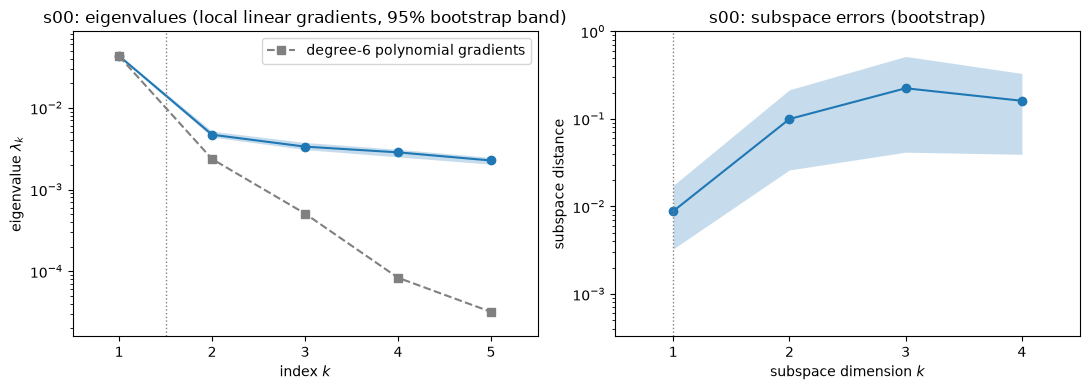

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ac.plotting.plot_eigenvalues(sub, ax=axs[0])
axs[0].plot(np.arange(1, m + 1), lp, 's--', color='gray', label='degree-6 polynomial gradients')
axs[0].set_ylim(lp.min() / 2, 2 * lam[0])
axs[0].legend()
ac.plotting.plot_subspace_errors(sub, ax=axs[1])
axs[0].set_title('s00: eigenvalues (local linear gradients, 95% bootstrap band)')
axs[1].set_title('s00: subspace errors (bootstrap)')
fig.tight_layout()
plt.close(fig)
fig

Left: eigenvalues with 95 % bootstrap bands (the band of $\lambda_1$ is [4.190e-02, 4.417e-02]) and, in gray,
the eigenvalues from the polynomial's gradients. Right: the bootstrap subspace error is small only for
$n = 1$ (median 0.0084, 95th percentile 0.0146); for $n = 2$ and $n = 3$ it is 0.0926 and 0.1993, because
eigenvalues 2–5 of the local linear estimate are close to one another. The bootstrap resamples fixed gradient
rows and so omits the local fits' error: its 95th percentile for $n = 1$ (0.0146) is below the distance to the
polynomial's direction (0.0255), so it understates the uncertainty of $w_1$.

bootstrap subspace error, median (95th percentile): n=1: 0.0084 (0.0146), n=2: 0.0926 (0.1923), n=3: 0.1993 (0.4748), n=4: 0.1465 (0.2985)

        w1      w2      w3      w4      w5  
x1    +0.0003  -0.1000  -0.0034  -0.6981  +0.7089
x2    -0.1366  +0.0631  +0.9728  +0.1187  +0.1304
x3    -0.9906  -0.0075  -0.1347  -0.0146  -0.0157
x4    +0.0030  +0.0657  -0.1815  +0.6949  +0.6927
x5    +0.0010  +0.9908  -0.0513  -0.1242  +0.0172


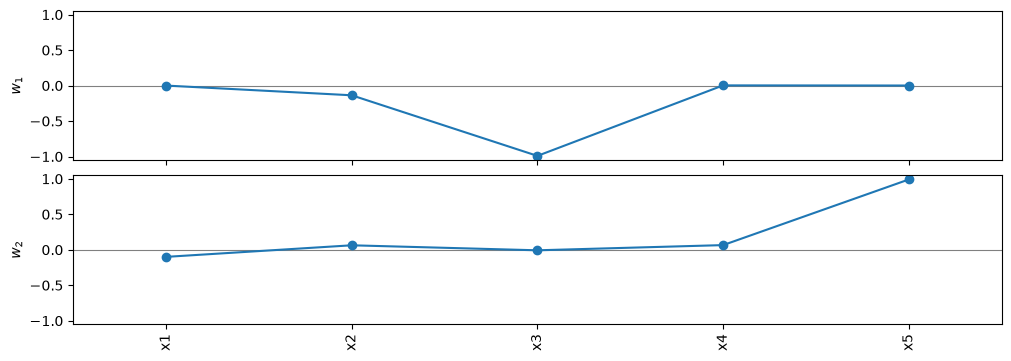

In [10]:
derr = sub.bootstrap_distances
print('bootstrap subspace error, median (95th percentile):',
      ', '.join(f'n={k + 1}: {np.median(derr[:, k]):.4f} ({np.percentile(derr[:, k], 95):.4f})'
                for k in range(derr.shape[1])))
W = sub.eigenvectors
print('\n      ' + '  '.join(f'  w{k + 1}  ' for k in range(m)))
for i, n in enumerate(NAMES):
    print(f'{n:5s} ' + '  '.join(f'{W[i, k]:+.4f}' for k in range(m)))
fig, axs = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=NAMES, figsize=(10, 3.5))
plt.close(fig)
fig

The first eigenvector (inputs scaled to $[-1, 1]$) is $w_1 = (+0.0003, -0.1366, -0.9906, +0.0030, +0.0010)$: $s_{00}$ decreases mainly
with $x_3$ and somewhat with $x_2$; $x_2$ and $x_3$ hold 0.99999 of $\|w_1\|^2$, and $x_1$, $x_4$, $x_5$ have
weights of at most 0.0030 in absolute value. The second eigenvector is mainly $x_5$ ($+0.9908$), and the polynomial's
$w_2$ (printed above) agrees, but its eigenvalue is a small share and its bootstrap error is large; the
remaining directions mix $x_1$ and $x_4$.

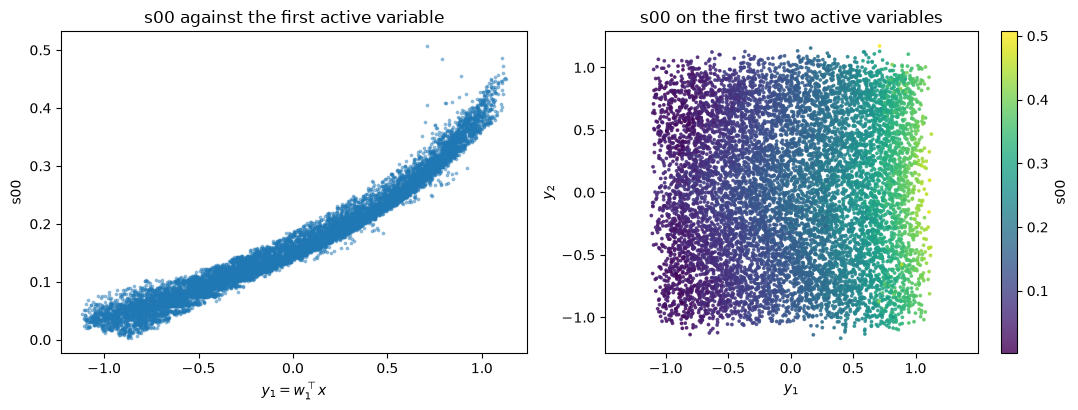

In [11]:
sub1 = ac.with_dimension(sub, 1)
sub2 = ac.with_dimension(sub, 2)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
ac.plotting.plot_sufficient_summary(sub1, X=X, f=f, qoi_label='s00', ax=axs[0],
                                    scatter_kw={'s': 3, 'alpha': 0.4})
ac.plotting.plot_sufficient_summary(sub2, X=X, f=f, qoi_label='s00', ax=axs[1],
                                    scatter_kw={'s': 3})
axs[0].set_title('s00 against the first active variable')
axs[1].set_title('s00 on the first two active variables')
fig.tight_layout()
plt.close(fig)
fig

Left: $s_{00}$ against $w_1^\top \mathbf{z}$ ($\mathbf{z}$ the inputs scaled to $[-1, 1]$) is a tight, monotone, curved
band; the vertical spread is what the other four directions add. Right: the colour of the two-variable plot
varies along the first axis and much less along the second.

In [12]:
# Choosing n: polynomial surrogates on n active variables, leave-one-out R^2 (the direction is fixed;
# with 10000 rows and at most 84 coefficients a refit of W per fold would change it very little).
for n, deg in [(1, 6), (2, 6), (3, 4)]:
    s_n = ac.with_dimension(sub, n)
    r2 = ac.fit_surrogate(X=X, f=f, subspace=s_n, kind='poly', degree=deg).loo_r_squared
    print(f'n = {n}, degree {deg}: LOO R^2 = {r2:.4f}')
print('all five inputs, degree 6: LOO R^2 = %.4f' % p6.loo_r_squared)
share = lam / lam.sum()
print('eigenvalue shares:', ' '.join(f'{v:.4f}' for v in share))
print('share of x2 and x3 in w1: %.5f' % (W[1, 0]**2 + W[2, 0]**2))
print('LOO R^2 gain from the second active variable: %.4f' % (ac.fit_surrogate(X=X, f=f, subspace=sub2, kind='poly', degree=6).loo_r_squared
                                                      - ac.fit_surrogate(X=X, f=f, subspace=sub1, kind='poly', degree=6).loo_r_squared))

n = 1, degree 6: LOO R^2 = 0.9758
n = 2, degree 6: LOO R^2 = 0.9874
n = 3, degree 4: LOO R^2 = 0.9942
all five inputs, degree 6: LOO R^2 = 0.9970
eigenvalue shares: 0.7661 0.0833 0.0596 0.0507 0.0403
share of x2 and x3 in w1: 0.99999
LOO R^2 gain from the second active variable: 0.0116


**Dimension.** $n = 1$ for $s_{00}$, chosen from the surrogate fits and the stability of $w_1$, not from the
pattern of the later local-linear ratios (which is the local fits' noise). A degree-6 polynomial of the one
active variable gives leave-one-out $R^2$ 0.9758; a second variable raises it to 0.9874 and a third (degree 4)
to 0.9942, against 0.9970 for all five inputs. $\lambda_1$ is 0.7661 of the local linear eigenvalue sum. The
first gap is 9.19–24.41 by the local estimates (8 to 40 neighbours) and 18.1 by the polynomial, and $w_1$ is
the same in all of them. The polynomial spectrum has further gaps ($\lambda_2/\lambda_3 = 4.65$,
$\lambda_3/\lambda_4 = 6.09$), so the first gap is not the only one; $n = 2$ (second direction mainly $x_5$) is a
defensible alternative, but it adds only 0.0116 to the leave-one-out $R^2$, and its direction is poorly
determined by the local estimate (bootstrap subspace error 0.0926 at $n = 2$ against 0.0084 at $n = 1$).

In [13]:
# Robustness to the design's structure: the same estimate from the rows that have no input value on a
# cell boundary, and from each half of a random split of the rows.
keep = ~on_edge.any(1)
Gk = ac.local_linear_gradients(X=X[keep], f=f[keep], space=space)
sub_k = ac.active_subspace(grads=Gk, space=space, estimator='as')
lk = sub_k.eigenvalues
print(f'rows without boundary values: {keep.sum()}; lambda_1/lambda_2 = {lk[0] / lk[1]:.2f}; '
      f'distance to the full-data W1: {dist(sub.eigenvectors, sub_k.eigenvectors, 1):.4f}')
half = np.random.default_rng(SEED).permutation(M)[: M // 2]
for name, rows in [('first half', half), ('second half', np.setdiff1d(np.arange(M), half))]:
    Gh = ac.local_linear_gradients(X=X[rows], f=f[rows], space=space)
    sh = ac.active_subspace(grads=Gh, space=space, estimator='as')
    print(f'{name}: lambda_1/lambda_2 = {sh.eigenvalues[0] / sh.eigenvalues[1]:.2f}; '
          f'distance to the full-data W1: {dist(sub.eigenvectors, sh.eigenvectors, 1):.4f}')

rows without boundary values: 4749; lambda_1/lambda_2 = 9.85; distance to the full-data W1: 0.0181


first half: lambda_1/lambda_2 = 9.83; distance to the full-data W1: 0.0107


second half: lambda_1/lambda_2 = 8.26; distance to the full-data W1: 0.0216


The direction does not depend on the design's boundary rows or on which half of the rows is used: from the
4749 rows with no value on a cell boundary, $\lambda_1/\lambda_2 = 9.85$ and the distance to the full-data
$w_1$ is 0.0181; the two random halves give ratios 9.83 and 8.26 and distances 0.0107 and 0.0216.

## All fifteen scalars

The same estimate (local linear gradients, no bootstrap) for every column, with the first gap from the
degree-6 polynomial's gradients in parentheses, the first eigenvector, and the leave-one-out $R^2$ of
degree-6 polynomials on one and two active variables and on all five inputs.

In [14]:
rows = []
for j, n in enumerate(SNAMES):
    fj = S[:, j]
    Gj = ac.local_linear_gradients(X=X, f=fj, space=space)
    sj = ac.orient(ac.active_subspace(grads=Gj, space=space, estimator='as'), by='mean_gradient',
                   grads=Gj, columns=1)
    pj = ac.fit_surrogate(X=X, f=fj, space=space, subspace=None, kind='poly', degree=6)
    lpj = ac.active_subspace(grads=ac.predict_gradient(pj, X), space=space, estimator='as').eigenvalues
    l = sj.eigenvalues
    r1 = ac.fit_surrogate(X=X, f=fj, subspace=ac.with_dimension(sj, 1), kind='poly', degree=6).loo_r_squared
    r2 = ac.fit_surrogate(X=X, f=fj, subspace=ac.with_dimension(sj, 2), kind='poly', degree=6).loo_r_squared
    rows.append((n, l[0] / l[1], l[1] / l[2], lpj[0] / lpj[1], sj.eigenvectors[:, 0], r1, r2, pj.loo_r_squared))
print('col   l1/l2 l2/l3 (poly l1/l2)   w1 (x1 .. x5)                         LOO R2: n=1    n=2    all 5')
for n, a, b, c, w, r1, r2, r5 in rows:
    print(f'{n:5s} {a:6.1f} {b:5.1f} ({c:7.1f})   ' + ' '.join(f'{v:+.3f}' for v in w)
          + f'   {r1:.4f} {r2:.4f} {r5:.4f}')
w15 = np.array([r[4] for r in rows])
print('\nlargest |weight| of x1, x4, x5 in any w1: %.4f' % np.abs(w15[:, [0, 3, 4]]).max())
r1s = np.array([r[5] for r in rows]); r5s = np.array([r[7] for r in rows])
print('mean LOO R^2 over the 15 columns: one active variable %.4f, all five inputs %.4f' % (r1s.mean(),
                                                                                          r5s.mean()))

# Which inputs are needed: degree-6 polynomials in (x2, x3) only, and in (x2, x3, x5)
print('\nLOO R^2, degree-6 polynomial in  (x2, x3)  (x2, x3, x5)')
for name in ['s00', 's03', 's07', 's09', 's14']:
    j = SNAMES.index(name)
    r = [ac.fit_surrogate(X=X[:, c], f=S[:, j], space=ac.Uniform(LOWER[c], UPPER[c]), subspace=None,
                          kind='poly', degree=6).loo_r_squared for c in ([1, 2], [1, 2, 4])]
    print(f'{name:5s} {r[0]:24.4f} {r[1]:13.4f}')

col   l1/l2 l2/l3 (poly l1/l2)   w1 (x1 .. x5)                         LOO R2: n=1    n=2    all 5
s00      9.2   1.4 (   18.1)   +0.000 -0.137 -0.991 +0.003 +0.001   0.9758 0.9874 0.9970
s01     13.6  11.2 (   13.5)   +0.000 -0.360 -0.933 -0.000 +0.001   0.9592 0.9996 1.0000
s02     13.3  10.9 (   13.2)   +0.000 -0.367 -0.930 -0.000 +0.001   0.9587 0.9995 1.0000
s03      3.9   1.9 (    4.0)   -0.001 -0.306 -0.952 -0.003 +0.011   0.8524 0.9203 0.9992
s04      6.0   2.6 (    5.9)   +0.002 +0.600 +0.800 -0.000 +0.006   0.9288 0.9723 0.9999
s05     17.5   3.3 (   19.0)   +0.002 -0.171 +0.985 +0.001 +0.006   0.9708 0.9888 0.9997
s06     14.0  12.6 (   13.9)   +0.000 -0.350 -0.937 -0.000 +0.001   0.9598 0.9998 1.0000
s07      7.5   3.2 (    8.7)   +0.005 -0.170 +0.985 +0.005 +0.015   0.8862 0.9795 0.9952
s08      7.5   3.2 (    8.7)   +0.005 -0.170 +0.985 +0.005 +0.015   0.8862 0.9795 0.9952
s09      2.8   3.9 (    3.1)   +0.008 -0.162 +0.987 -0.008 +0.006   0.8555 0.9760 0.9961
s10     18.

s00                     0.9802        0.9966


s03                     0.9269        0.9974


s07                     0.8931        0.9874


s09                     0.8658        0.9883


s14                     0.9996        1.0000


In every column $w_1$ lies in the $(x_2, x_3)$ plane: the largest weight of $x_1$, $x_4$ or $x_5$ in any $w_1$
is 0.0150 in absolute value. The first gap ranges from 2.8 ($s_{09}$) to 340.1 ($s_{14}$, which is close to a
function of $-0.810\,z_2 + 0.587\,z_3$, $z$ the inputs scaled to $[-1, 1]$, with $R^2$ 0.9994 on one variable). Where the local-linear
and polynomial gaps differ most ($s_{11}$: 4.0 against 15.3), the local fits' error sets the second eigenvalue.
Columns $s_{01}, s_{02}, s_{06}, s_{13}$ and $s_{03}, s_{04}, s_{07}, s_{08}, s_{09}, s_{12}$ need a second
active variable: their two-variable $R^2$ is 0.9203–1.0000 against 0.8524–0.9610 on one. Over the fifteen
columns the mean leave-one-out $R^2$ is 0.9366 on one active variable and 0.9983 on all five inputs. The first direction lies in the $(x_2, x_3)$ plane, but several outputs also depend on $x_5$: a degree-6
polynomial in $(x_2, x_3)$ alone has leave-one-out $R^2$ 0.8931 for $s_{07}$, 0.8658 for $s_{09}$ and 0.9269 for
$s_{03}$, and adding $x_5$ raises these to 0.9874, 0.9883 and 0.9974 ($s_{00}$: 0.9802 and 0.9966), in line with
$w_2 \approx x_5$ for $s_{00}$.

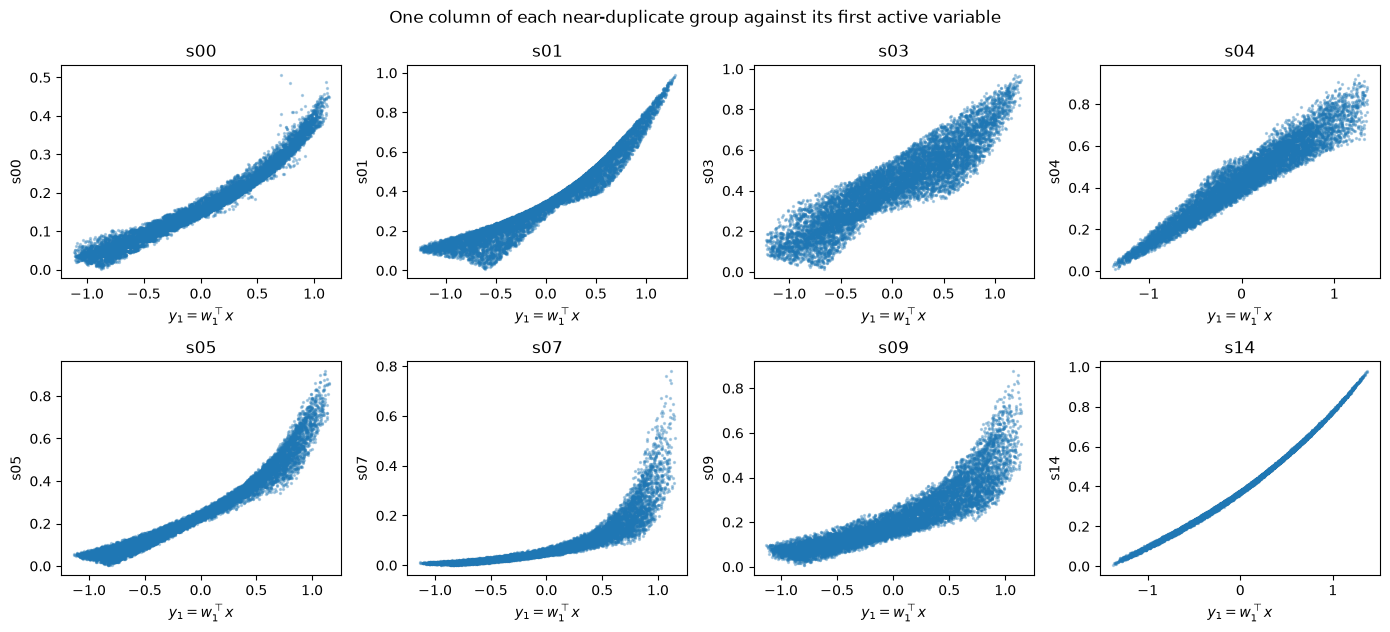

In [15]:
fig, axs = plt.subplots(2, 4, figsize=(14, 6.4))
for ax, j in zip(axs.ravel(), REPS):
    Gj = ac.local_linear_gradients(X=X, f=S[:, j], space=space)
    sj = ac.orient(ac.active_subspace(grads=Gj, space=space, estimator='as', n=1), by='mean_gradient',
                   grads=Gj, columns=1)
    ac.plotting.plot_sufficient_summary(sj, X=X, f=S[:, j], qoi_label=SNAMES[j], ax=ax,
                                        scatter_kw={'s': 2, 'alpha': 0.3})
    ax.set_title(SNAMES[j])
fig.suptitle('One column of each near-duplicate group against its first active variable')
fig.tight_layout()
plt.close(fig)
fig

The eight panels (one column per group of near-duplicates) show the same picture: curved, mostly monotone
bands with a spread that the second direction removes for $s_{01}$, $s_{07}$ and $s_{09}$.

## Comparison with the paper

The paper builds neural-network surrogates and reports no sensitivity or subspace analysis; the comparison
covers what both describe.

| quantity | paper (arXiv v1) | this notebook |
|---|---|---|
| number of inputs | 5 (p. 4) | 5 |
| input names, units, ranges | not reported | not released; box read from the data |
| design | random 100K subset of a 1M Latin hypercube; 10K validation set (pp. 4–5) | 10,000 released rows; not a plain random LHS subset (cell-boundary clusters, translated rows) |
| scalar outputs | 15 (p. 4) | 15, in eight near-duplicate groups |
| mean $R^2$ over the 15 scalars | 0.9990 (baseline network), 0.9974 (MaCC), 10K validation set (Table 1, p. 6) | 0.9983 (degree-6 polynomial in all 5 inputs, leave-one-out on the 10,000 rows); 0.9366 (polynomial in one active variable) |
| active subspace, input importance | not reported | $w_1$ in the $(x_2, x_3)$ plane for all 15 scalars |

The $R^2$ values are not like for like: the paper's networks were trained on 100,000 runs and tested on
10,000, and predict all outputs jointly; the notebook's polynomials are fitted to the 10,000 released runs and
scored by leave-one-out. They agree that the scalars are easy to predict from the five inputs ("both models
achieving an R2 score of ∼0.99", p. 5).

In [16]:
print('notebook run time: %.0f s' % (time.perf_counter() - t_start))

notebook run time: 489 s


## References

- R. Anirudh, J. J. Thiagarajan, P.-T. Bremer, B. K. Spears, Improved surrogates in inertial confinement fusion
  with manifold and cycle consistencies, *Proc. Natl. Acad. Sci. USA* 117(18):9741–9746, 2020.
  [doi:10.1073/pnas.1916634117](https://doi.org/10.1073/pnas.1916634117) (preprint arXiv:1912.08113).
- J. A. Gaffney, R. Anirudh, P.-T. Bremer, J. Hammer, D. Hysom, S. A. Jacobs, J. L. Peterson, P. Robinson,
  B. K. Spears, P. T. Springer, J. J. Thiagarajan, B. Van Essen, J.-S. Yeom, *The JAG inertial confinement
  fusion simulation dataset for multi-modal scientific deep learning*, LLNL Open Data Initiative, UC San Diego
  Library Digital Collections, 2020, [doi:10.6075/J0RV0M27](https://doi.org/10.6075/J0RV0M27) (dataset
  citation as given in the repository's README; the record was not read).
- Data and code: https://github.com/llnl/macc (commit a0318c2), MIT licence.
- P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM,
  2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)

## Acknowledgments

The paper's work was performed under the auspices of the U.S. Department of Energy by Lawrence Livermore
National Laboratory under Contract DE-AC52-07NA27344 (arXiv v1, p. 7); the published article's Crossref record
lists LLNL Laboratory Directed Research and Development funding, award 18-SI-002.